# 2026-10-12: Blind pre-peak rSFMS reference and SF excess across galaxies

Fit the eight pre-peak **product IDs** with equal total weight per product,
measure the requested error-corrected absolute-residual width, then apply the
same frozen line and width to all selected pre-peak and close-to-peak SF spaxels.
There is no preferred galaxy, direction, spatial region, or H I alignment in
the selection. The catalogue stage labels define the reference population.

The sample uses catalogue inclination **<80 degrees**. NGC4567_8 is retained
as one combined product/weight unit; it contains two physical galaxies, so
"equal galaxy weight" here means equal product-ID weight. NGC4383 is retained.
The whole available SF footprint is used, with no radial or Fourier-coverage
cut. Products, masks, and geometry are loaded from the live local tree.

This is an exploratory, descriptive comparison. Pre-peak residuals are measured
against their own fitted reference, whereas close-to-peak galaxies are external
to the fit. No causal RPS inference or spaxel-independent significance test is
made. The original NGC4654 notebook is preserved.

In [1]:
from pathlib import Path
import hashlib, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display, Markdown

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
GALAXY_COLOR_PATH = PROJECT_ROOT / 'MAUVE_galaxy_colors.dat'
I_MAX_EXCLUSIVE = 80.0
EW_HA_MIN = 6.0
HALPHA_SIGMA_MAX = 45.0
WCS_TOLERANCE_ARCSEC = 0.05
MASS_HDU = 'LOGMASS_SURFACE_DENSITY'
BIN_HDU_MASS = 'BINID'
BIN_HDU_GAS = 'BIN_ID'
SFR_HDU_PRIMARY = 'LOGSFR_SURFACE_DENSITY_HII'
EW_HDU = 'PROXY_EWHA'
HALPHA_SIGMA_OBS_HDU = 'HA6562_SIGMA'
HALPHA_SIGMA_CORR_HDU = 'HA6562_SIGMA_CORR'
MASK_TABLE_HDU = 'MASKFILE'
MASK_COLUMN = 'MASK'
MASS_FILE_PATTERN = '{galid}_spatial_binning_maps_further.fits'
SFR_FILE_PATTERNS = ('{galid}_gas_bin_maps_further.fits', '{galid}_gas_BIN_maps_further.fits')
EW_FILE_PATTERNS = ('{galid}_proxy_EW_maps_further.fits', '{galid}_proxy_EW_maps.fits')
MASK_FILE_PATTERN = '{galid}_mask.fits'
MAP_LIMIT = 4.0  # display saturation only; fractions/histograms use all values
mpl.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})

## 1. Live sample, embedded helpers, and SF/error provenance

Inherited SF selection: finite HII log SFR and stellar density, unmasked usable
footprint, proxy EW(Halpha)>6 Angstrom, and 0<intrinsic Halpha dispersion<45 km/s.
Intrinsic dispersion is sqrt(observed dispersion squared minus correction
squared). No additional SFR-error cut is imposed on fitting or excess maps.

The current products have no dedicated SFR-error HDU. Since SFR is proportional
to corrected Halpha flux, derive the first-order log SFR error in dex as
`HA6562_FLUX_ERR_CORR / (HA6562_FLUX_CORR * ln(10))`. Use the existing corrected
flux uncertainty, which includes the pipeline's dust-error treatment; do not
add that term again. Fixed conversion/area factors cancel in the relative error.
Distance, inclination, calibration systematics, stellar-density errors, and
fitted-line uncertainty are not included. Invalid/negative errors are excluded
only from width estimation and their counts are displayed.

In [2]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak",
        "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        names = {h.name.upper() for h in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa = WCS(header_a).celestial
    wb = WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    """Return min elliptical R/Re over physical components (union geometry for NGC4567_8)."""
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, row in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(ra, dec, row.center_ra_deg, row.center_dec_deg)
        pa = np.deg2rad(float(row.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        r = np.sqrt((major / float(row.a_re_arcsec)) ** 2 + (minor / float(row.b_re_arcsec)) ** 2)
        radius = np.minimum(radius, r)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def make_valid_disc_mask(log_sigma_star, bin_id, ngist_mask, radius_re):
    return (
        np.isfinite(log_sigma_star)
        & np.isfinite(bin_id)
        & (ngist_mask == 0)
        & np.isfinite(radius_re)
    )

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma_obs = np.asarray(sigma_obs, dtype=float)
    sigma_corr = np.asarray(sigma_corr, dtype=float)
    if sigma_obs.shape != sigma_corr.shape:
        raise ValueError(
            f"Observed/correction Halpha sigma shape mismatch: {sigma_obs.shape} vs {sigma_corr.shape}"
        )
    sigma2_intrinsic = sigma_obs**2 - sigma_corr**2
    sigma_intrinsic = np.full(sigma_obs.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2_intrinsic) & (sigma2_intrinsic > 0)
    sigma_intrinsic[valid] = np.sqrt(sigma2_intrinsic[valid])
    return sigma_intrinsic

def make_sf_mask(valid_disc_mask, log_sigma_sfr, ew_ha, halpha_sigma_intrinsic):
    """Project SF definition: HII/SF map + EW(Halpha)>6 A + intrinsic sigma<45 km/s."""
    return (
        valid_disc_mask
        & np.isfinite(log_sigma_sfr)
        & np.isfinite(ew_ha)
        & (ew_ha > EW_HA_MIN)
        & np.isfinite(halpha_sigma_intrinsic)
        & (halpha_sigma_intrinsic < HALPHA_SIGMA_MAX)
    )

def load_galaxy_maps(row, geometry, sfr_hdu=SFR_HDU_PRIMARY):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, sfr_hdu)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    halpha_sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    halpha_sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    shapes = {
        mass.shape, mass_bin.shape, gas_bin.shape, sfr.shape, ew_ha.shape,
        halpha_sigma_obs.shape, halpha_sigma_corr.shape,
    }
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    if components.empty:
        raise KeyError(f"{row.GALID}: no geometry rows")
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    halpha_sigma_intrinsic = intrinsic_sigma_from_maps(halpha_sigma_obs, halpha_sigma_corr)
    valid = make_valid_disc_mask(mass, gas_bin, ngist_mask, radius_re)
    classification = valid & np.isfinite(sfr)
    sf = make_sf_mask(valid, sfr, ew_ha, halpha_sigma_intrinsic)
    return {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "ew_ha": ew_ha,
        "halpha_sigma_intrinsic": halpha_sigma_intrinsic,
        "mass_bin_id": mass_bin,
        "gas_bin_id": gas_bin,
        "ngist_mask": ngist_mask,
        "radius_re": radius_re,
        "valid_disc_mask": valid,
        "classification_mask": classification,
        "sf_mask": sf,
        "wcs_separation_arcsec": wcs_sep,
    }

def load_galaxy_colors(path):
    """Read the fixed, project-approved MAUVE galaxy colour mapping."""
    colors = {}
    for line in path.read_text().splitlines():
        fields = line.split()
        if not fields or fields[0].startswith("#") or fields[0] == "reserved":
            continue
        if fields[0] == "alias":
            colors[fields[1]] = fields[3]
        elif fields[0].isdigit():
            colors[fields[1]] = fields[3]
    return colors

def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        required = {"Galaxy", "logMstar", "class"}
        missing = required - set(table.names)
        if missing:
            raise KeyError(f"{path}: missing catalogue columns {sorted(missing)}")
        frame = pd.DataFrame({
            "galaxy": [str(v).strip() for v in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame

def discover_products(data_root):
    rows = []
    for folder in sorted(p for p in data_root.iterdir() if p.is_dir() and not p.name.endswith("_logs")):
        galid = folder.name
        mass_base = folder / MASS_FILE_PATTERN.format(galid=galid)
        mass = first_existing([mass_base, Path(str(mass_base)+'.gz')]) or mass_base
        sfr_paths = [folder / p.format(galid=galid) for p in SFR_FILE_PATTERNS]
        sfr = first_existing(sfr_paths + [Path(str(p)+'.gz') for p in sfr_paths])
        ew_paths = [folder / p.format(galid=galid) for p in EW_FILE_PATTERNS]
        ew = first_existing(ew_paths + [Path(str(p)+'.gz') for p in ew_paths])
        mask_base = folder / MASK_FILE_PATTERN.format(galid=galid)
        mask = first_existing([mask_base, Path(str(mask_base)+'.gz')]) or mask_base
        rows.append({"GALID": galid, "mass_path": mass, "sfr_path": sfr, "ew_path": ew, "mask_path": mask})
    return pd.DataFrame(rows)

In [3]:
SOURCE_NAME = '20261010_check_NGC4654_blind_SF_asymmetry_enhancement.ipynb'
SOURCE_SHA256_AT_CREATION = '7bfe860f9ab0ecdbaf2024fdcbbfdbe9590c88d9a5ecf4d4a495550655d40960'
print('Embedded helper source:', SOURCE_NAME, SOURCE_SHA256_AT_CREATION)
for p in (CATALOG_PATH, GEOMETRY_PATH, GALAXY_COLOR_PATH):
    print(p.name, hashlib.sha256(p.read_bytes()).hexdigest())
master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH).merge(master[['galaxy', 'logMstar', 'stage']],
    on='galaxy', how='left', validate='one_to_one')
assert geometry.stage.notna().all()
assert geometry.stage.eq(geometry.mauve_infall_stage.map(normalise_stage_label)).all()
meta = []
for galid, group in geometry.groupby('notebook_product_id', sort=True):
    if group.stage.nunique() != 1:
        raise ValueError(f'{galid}: mixed stages within combined product')
    meta.append(dict(GALID=galid, stage=group.stage.iloc[0],
        n_components=len(group), inclination=group.inclination_deg.max()))
inventory = pd.DataFrame(meta).merge(discover_products(DATA_ROOT), on='GALID',
    how='outer', validate='one_to_one')
inventory['included'] = (inventory.stage.isin(['pre-peak', 'close-to-peak'])
    & inventory.inclination.lt(I_MAX_EXCLUSIVE))
inventory['selection_reason'] = np.where(inventory.included, 'selected',
    np.where(~inventory.stage.isin(['pre-peak','close-to-peak']),
             'outside requested stages / missing metadata', 'inclination >=80 / missing'))
display(inventory[['GALID','stage','n_components','inclination','selection_reason']])
selected = inventory.loc[inventory.included].copy()
pre_ids = sorted(selected.loc[selected.stage.eq('pre-peak'), 'GALID'])
close_ids = sorted(selected.loc[selected.stage.eq('close-to-peak'), 'GALID'])
print('Pre-peak:', len(pre_ids), pre_ids)
print('Close-to-peak:', len(close_ids), close_ids)
assert len(pre_ids) == 8 and len(close_ids) == 5, 'Requested 8/5 sample changed: review inventory'
galaxy_colors = load_galaxy_colors(GALAXY_COLOR_PATH)
assert all(g in galaxy_colors for g in pre_ids + close_ids)

Embedded helper source: 20261010_check_NGC4654_blind_SF_asymmetry_enhancement.ipynb 7bfe860f9ab0ecdbaf2024fdcbbfdbe9590c88d9a5ecf4d4a495550655d40960
mauve_master_wiki_newclass.fits 05fbc2ba45b6cde2b02e67b6a06f646491b642c009186f0cd5176b9dc6e5af0c
MAUVE_effective_radii.csv e7f0300c43376fbc0d35977b4512a57b84169b8472b3febaba7bf67851d60111
MAUVE_galaxy_colors.dat 18874f26dacd3b5e8113574d7ba1d90a57cac19a6f4efa22673e76dc649dbab4
Pre-peak: 8 ['NGC4189', 'NGC4254', 'NGC4294', 'NGC4321', 'NGC4351', 'NGC4383', 'NGC4535', 'NGC4567_8']
Close-to-peak: 5 ['NGC4298', 'NGC4424', 'NGC4501', 'NGC4654', 'NGC4694']


,GALID,stage,n_components,inclination,selection_reason
0,IC3392,post-peak,1,68,outside requested stages / missing metadata
1,NGC4064,post-peak,1,70,outside requested stages / missing metadata
2,NGC4189,pre-peak,1,42,selected
3,NGC4192,pre-peak,1,83,inclination >=80 / missing
4,NGC4216,post-peak,1,90,outside requested stages / missing metadata
5,NGC4222,pre-peak,1,90,inclination >=80 / missing
6,NGC4254,pre-peak,1,39,selected
7,NGC4293,post-peak,1,67,outside requested stages / missing metadata
8,NGC4294,pre-peak,1,74,selected
9,NGC4298,close-to-peak,1,52,selected


In [4]:
samples, galaxy_maps, qc_rows = {}, {}, []
for row in selected.itertuples(index=False):
    for label in ('mass', 'sfr', 'ew', 'mask'):
        p = getattr(row, label + '_path')
        if not isinstance(p, Path) or not p.exists():
            raise FileNotFoundError(f'{row.GALID}: missing {label}: {p}')
    maps = load_galaxy_maps(row, geometry)
    _, header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    _, ew_header = load_fits_map(row.ew_path, EW_HDU, return_header=True)
    ew_sep = celestial_wcs_separation_arcsec(header, ew_header, maps['sf_mask'].shape)
    if not np.isfinite(ew_sep) or ew_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f'{row.GALID}: EW WCS mismatch: {ew_sep} arcsec')
    flux = load_fits_map(row.sfr_path, 'HA6562_FLUX_CORR')
    flux_err = load_fits_map(row.sfr_path, 'HA6562_FLUX_ERR_CORR')
    assert flux.shape == flux_err.shape == maps['sf_mask'].shape
    error_ok = np.isfinite(flux) & (flux > 0) & np.isfinite(flux_err) & (flux_err >= 0)
    err = np.full(flux.shape, np.nan)
    err[error_ok] = flux_err[error_ok] / flux[error_ok] / np.log(10.0)
    sf = maps['sf_mask']
    if not sf.any(): raise ValueError(f'{row.GALID}: no selected SF spaxels')
    # Check proportionality of stored log SFR to corrected Halpha on selected SF.
    delta_conversion = maps['log_sigma_sfr'][sf] - np.log10(flux[sf])
    assert np.isfinite(delta_conversion).all()
    conversion_range = np.ptp(delta_conversion)
    assert conversion_range < 1e-5, f'{row.GALID}: SFR/flux proportionality changed'
    yy, xx = np.indices(sf.shape)
    samples[row.GALID] = pd.DataFrame(dict(GALID=row.GALID, stage=row.stage,
        x=maps['log_sigma_star'][sf], y=maps['log_sigma_sfr'][sf],
        sfr_err_dex=err[sf], pixel_x=xx[sf], pixel_y=yy[sf]))
    maps['header'] = header
    galaxy_maps[row.GALID] = maps
    qc_rows.append(dict(GALID=row.GALID, stage=row.stage, N_SF=int(sf.sum()),
        N_valid_error=int(np.isfinite(err[sf]).sum()),
        N_invalid_error=int((~np.isfinite(err[sf])).sum()),
        mass_gas_WCS_arcsec=maps['wcs_separation_arcsec'], EW_WCS_arcsec=ew_sep,
        SFR_flux_log_conversion_range=conversion_range))
    print(row.GALID, 'loaded:', int(sf.sum()), 'SF spaxels')
qc = pd.DataFrame(qc_rows)
display(qc)

NGC4189 loaded: 96364 SF spaxels
NGC4254 loaded: 661963 SF spaxels
NGC4294 loaded: 68833 SF spaxels
NGC4298 loaded: 144157 SF spaxels
NGC4321 loaded: 454131 SF spaxels
NGC4351 loaded: 30711 SF spaxels
NGC4383 loaded: 25212 SF spaxels
NGC4424 loaded: 8994 SF spaxels
NGC4501 loaded: 251936 SF spaxels
NGC4535 loaded: 187113 SF spaxels
NGC4567_8 loaded: 222533 SF spaxels
NGC4654 loaded: 345036 SF spaxels
NGC4694 loaded: 1058 SF spaxels


,GALID,stage,N_SF,N_valid_error,N_invalid_error,mass_gas_WCS_arcsec,EW_WCS_arcsec,SFR_flux_log_conversion_range
0,NGC4189,pre-peak,96364,96364,0,0.0,0.0,8.881784e-16
1,NGC4254,pre-peak,661963,661963,0,0.0,0.0,1.776357e-15
2,NGC4294,pre-peak,68833,68833,0,0.0,0.0,1.776357e-15
3,NGC4298,close-to-peak,144157,144157,0,0.0,0.0,8.881784e-16
4,NGC4321,pre-peak,454131,454131,0,0.0,0.0,8.881784e-16
5,NGC4351,pre-peak,30711,30711,0,0.0,0.0,8.881784e-16
6,NGC4383,pre-peak,25212,25212,0,0.0,0.0,8.881784e-16
7,NGC4424,close-to-peak,8994,8994,0,0.0,0.0,1.776357e-15
8,NGC4501,close-to-peak,251936,251936,0,0.0,0.0,8.881784e-16
9,NGC4535,pre-peak,187113,187113,0,0.0,0.0,8.881784e-16


## 2. Equal-galaxy fit and requested intrinsic-width recipe

Let x=log10 stellar surface density [Msun/kpc2], y=log10 SFR surface density
[Msun/yr/kpc2], and f(x)=a x+b. Fit by minimizing
sum_g (1/N_g) sum_i [y_gi-f(x_gi)]^2 over pre-peak galaxies only. No inverse-error
weighting or mass-range cut is applied. Residuals are vertical offsets in dex.

For each pre-peak SF spaxel with a valid error, compute

$$q_{gi}=\sqrt{\max\{[y_{gi}-f(x_{gi})]^2-\sigma_{y,gi}^2,0\}},\qquad
W=\frac1G\sum_g\frac1{N_{g,\mathrm{err}}}\sum_i q_{gi}.$$

This implements quadrature subtraction **per absolute offset, before averaging**.
Negative radicands contribute zero, not missing values; their fraction is
reported. Each galaxy has equal width weight even if its valid-error count
differs. W is the requested corrected mean absolute width, not an unbiased
intrinsic standard deviation. In particular sqrt(mean(residual^2-error^2)) is
a different statistic and is not substituted here.

In [5]:
pre = pd.concat([samples[g] for g in pre_ids], ignore_index=True)
counts = pre.groupby('GALID').GALID.transform('size').to_numpy()
weights = 1.0 / counts
x, y = pre.x.to_numpy(), pre.y.to_numpy()
x_center = np.average(x, weights=weights)
y_center = np.average(y, weights=weights)
denom = np.sum(weights * (x-x_center)**2)
assert denom > 0
slope = np.sum(weights * (x-x_center) * (y-y_center)) / denom
intercept = y_center - slope*x_center
pre['fit_weight'] = weights
np.testing.assert_allclose(pre.groupby('GALID').fit_weight.sum(), 1.0)
def rsfms(x): return slope*np.asarray(x) + intercept
pre['residual_dex'] = pre.y - rsfms(pre.x)
width_sample = pre.loc[np.isfinite(pre.sfr_err_dex) & pre.sfr_err_dex.ge(0)].copy()
assert set(width_sample.GALID) == set(pre_ids), 'Every reference galaxy needs valid errors'
width_sample['radicand'] = width_sample.residual_dex**2 - width_sample.sfr_err_dex**2
width_sample['corrected_abs_dex'] = np.sqrt(np.maximum(width_sample.radicand, 0.0))
width_by_galaxy = width_sample.groupby('GALID').agg(
    N_width=('corrected_abs_dex','size'), width_g_dex=('corrected_abs_dex','mean'),
    mean_abs_offset_dex=('residual_dex', lambda v: np.mean(np.abs(v))),
    mean_SFR_err_dex=('sfr_err_dex','mean'),
    fraction_clipped_to_zero=('radicand',lambda v: np.mean(v <= 0)))
width_dex = float(width_by_galaxy.width_g_dex.mean())
assert np.isfinite(width_dex) and width_dex > 0
display(width_by_galaxy)
print(f'Pre-peak rSFMS: log Sigma_SFR = {slope:.6f} log Sigma_star {intercept:+.6f}')
print(f'Requested intrinsic absolute width W = {width_dex:.6f} dex')
display(Markdown(f'**Pre-peak reference:** y = {slope:.4f} x {intercept:+.4f}; '
    f'**requested width W = {width_dex:.4f} dex**, from {len(pre_ids)} equal-weight products.'))

Pre-peak rSFMS: log Sigma_SFR = 0.959663 log Sigma_star -9.688218
Requested intrinsic absolute width W = 0.348002 dex


,N_width,width_g_dex,mean_abs_offset_dex,mean_SFR_err_dex,fraction_clipped_to_zero
GALID,,,,,
NGC4189,96364,0.326038,0.327801,0.020660,0.030364
NGC4254,661963,0.423458,0.424630,0.014498,0.026050
NGC4294,68833,0.303254,0.303878,0.010362,0.019133
NGC4321,454131,0.359966,0.361936,0.022674,0.032154
NGC4351,30711,0.336563,0.337573,0.018610,0.025040
NGC4383,25212,0.275312,0.275952,0.010178,0.011978
NGC4535,187113,0.440557,0.441522,0.020060,0.014825
NGC4567_8,222533,0.318869,0.321515,0.025772,0.048209


**Pre-peak reference:** y = 0.9597 x -9.6882; **requested width W = 0.3480 dex**, from 8 equal-weight products.

/private/tmp/run_prepeak_excess.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(b,format='png',dpi=110)


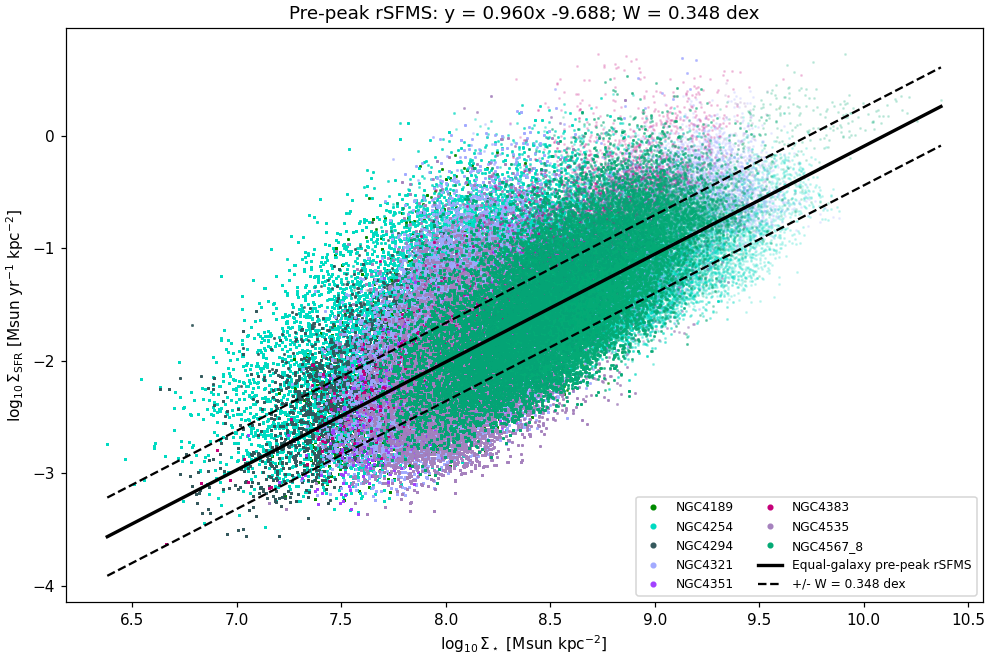

In [6]:
fig, ax = plt.subplots(figsize=(9,6), layout='constrained')
for g in pre_ids:
    f = samples[g]
    ax.scatter(f.x, f.y, color=galaxy_colors[g], s=1, alpha=.16, rasterized=True)
    # Opaque legend handles, independent of scatter transparency.
    ax.plot([], [], '.', color=galaxy_colors[g], label=g)
line_x = np.linspace(pre.x.min(), pre.x.max(), 300)
ax.plot(line_x, rsfms(line_x), color='black', lw=2.2, label='Equal-galaxy pre-peak rSFMS')
ax.plot(line_x, rsfms(line_x)+width_dex, color='black', ls='--', lw=1.5,
    label=f'+/- W = {width_dex:.3f} dex')
ax.plot(line_x, rsfms(line_x)-width_dex, color='black', ls='--', lw=1.5)
ax.set(xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
    ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
    title=f'Pre-peak rSFMS: y = {slope:.3f}x {intercept:+.3f}; W = {width_dex:.3f} dex')
ax.legend(fontsize=8, ncol=2)
plt.show()

OVERLAY_CHECKS_OK: 5 galaxies; all counts retained; common bins/colour scale


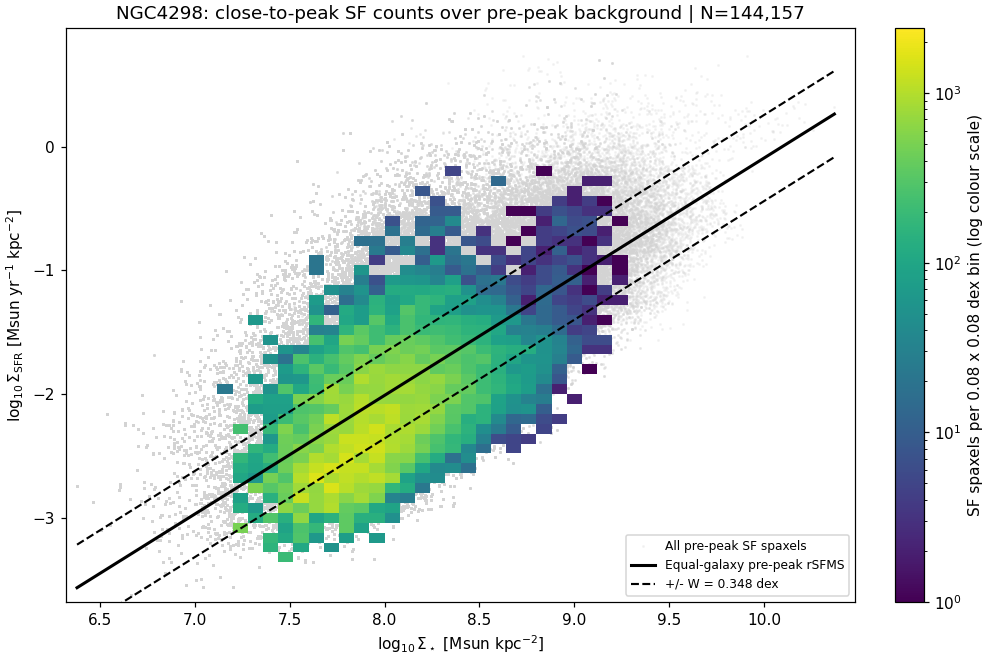

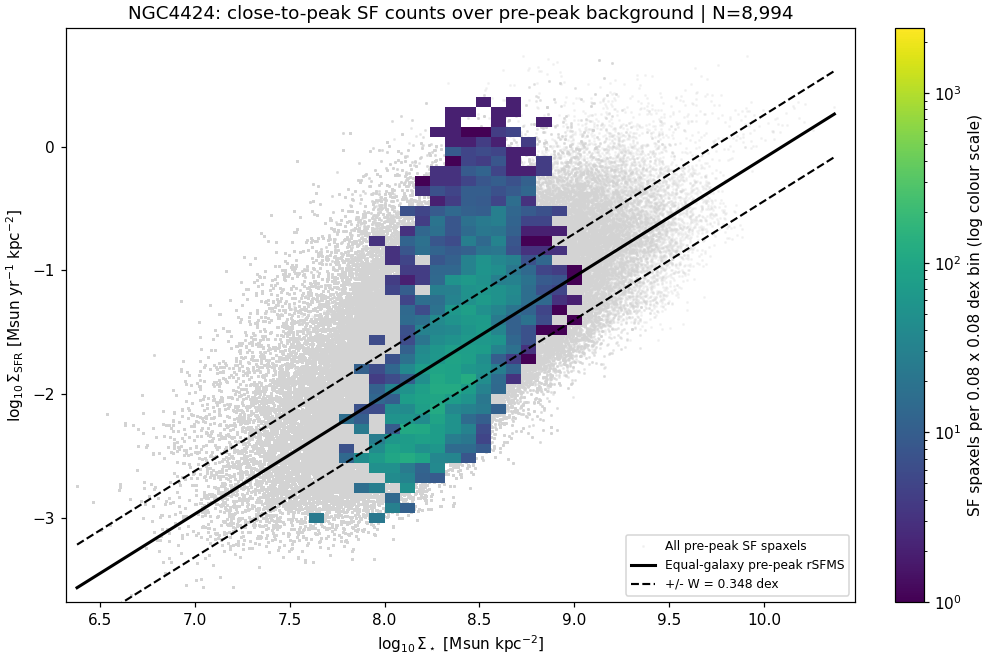

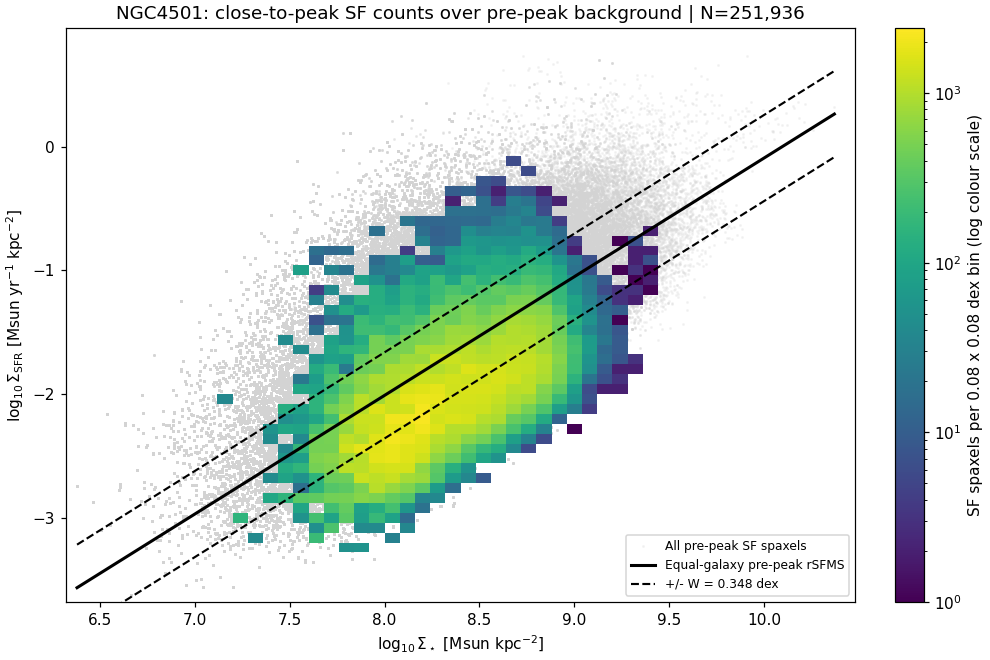

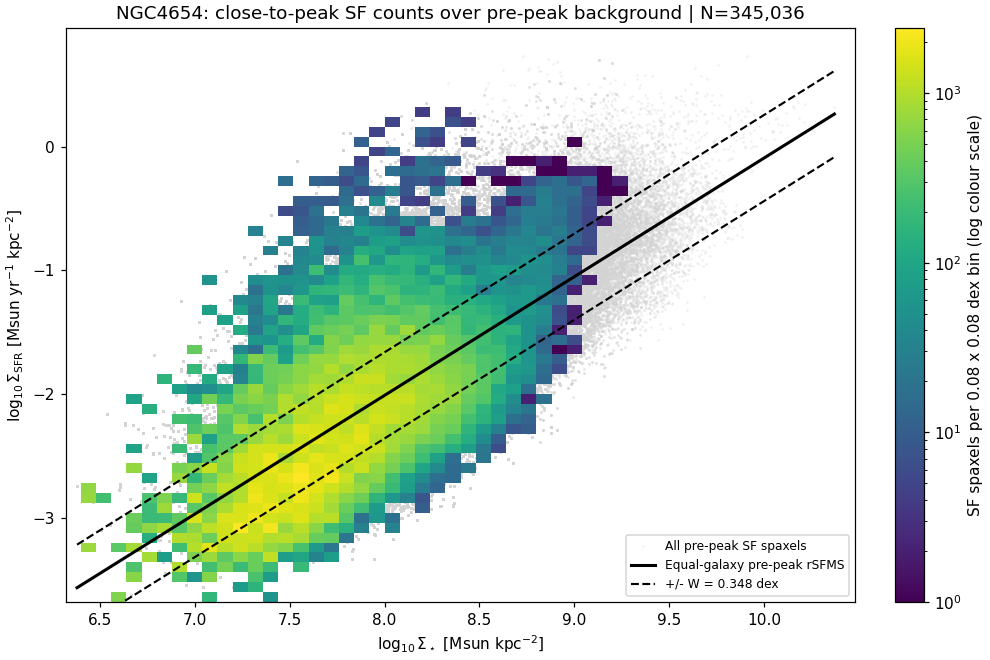

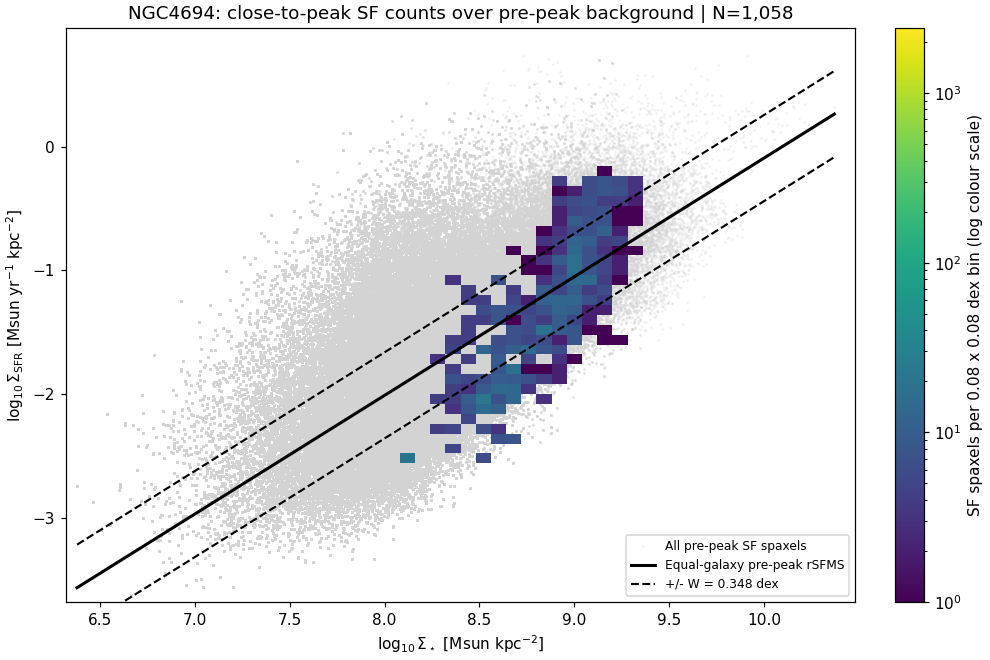

In [14]:
# One rSFMS density overlay per close-to-peak galaxy (full SF footprint).
# All pre-peak SF spaxels remain light-gray background dots.
# Identical 0.08-dex bins and a common logarithmic colour scale show raw counts.
# The outer-only exclusions later in the notebook do not apply to this plot.
from matplotlib.colors import LogNorm
overlay_bin_width_dex = 0.08
overlay_x_min = min(pre.x.min(), min(samples[g].x.min() for g in close_ids))
overlay_x_max = max(pre.x.max(), max(samples[g].x.max() for g in close_ids))
overlay_y_min = min(pre.y.min(), min(samples[g].y.min() for g in close_ids))
overlay_y_max = max(pre.y.max(), max(samples[g].y.max() for g in close_ids))
overlay_x_edges = np.arange(np.floor(overlay_x_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_x_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_y_edges = np.arange(np.floor(overlay_y_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_y_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_counts = {}
for g in close_ids:
    overlay_counts[g], _, _ = np.histogram2d(samples[g].x, samples[g].y,
        bins=(overlay_x_edges,overlay_y_edges))
    assert int(overlay_counts[g].sum()) == len(samples[g]), f'{g}: lost histogram spaxels'
overlay_norm = LogNorm(vmin=1, vmax=max(2, max(h.max() for h in overlay_counts.values())))
overlay_line_x = np.linspace(pre.x.min(),pre.x.max(),300)
for g in close_ids:
    fig, ax = plt.subplots(figsize=(9,6),layout='constrained')
    ax.scatter(pre.x,pre.y,s=1,color='lightgray',alpha=.20,rasterized=True,
        label='All pre-peak SF spaxels',zorder=1)
    h = overlay_counts[g]
    mesh = ax.pcolormesh(overlay_x_edges,overlay_y_edges,np.ma.masked_equal(h.T,0),
        cmap='viridis',norm=overlay_norm,shading='flat',rasterized=True,zorder=2)
    ax.plot(overlay_line_x,rsfms(overlay_line_x),color='black',lw=2,
        label='Equal-galaxy pre-peak rSFMS',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)+width_dex,color='black',ls='--',lw=1.4,
        label=f'+/- W = {width_dex:.3f} dex',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)-width_dex,color='black',ls='--',lw=1.4,zorder=3)
    ax.set(xlim=(overlay_x_edges[0],overlay_x_edges[-1]),
        ylim=(overlay_y_edges[0],overlay_y_edges[-1]),
        xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
        ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
        title=f'{g}: close-to-peak SF counts over pre-peak background | N={len(samples[g]):,}')
    fig.colorbar(mesh,ax=ax,label='SF spaxels per 0.08 x 0.08 dex bin (log colour scale)')
    ax.legend(fontsize=8,loc='lower right')
    plt.show()
print('OVERLAY_CHECKS_OK:',len(close_ids),'galaxies; all counts retained; common bins/colour scale')

## 3. Signed excess, spatial maps, and threshold fractions

Define E=[log10 Sigma_SFR - f(log10 Sigma_star)]/W. Positive means above the
pre-peak reference and negative means below it. E is dimensionless; E=1,2,3
does not mean 1,2,3-sigma significance. Width normalization is common to every
galaxy, with no per-galaxy refit or centering.

Maps show every selected SF spaxel on celestial WCS, with the same coolwarm
scale saturated at +/-4. Fractions use strict E>1, E>2, E>3 and all selected SF
spaxels as the denominator, including values outside the display range.
The table flags stellar densities outside the full pre-peak x range, where
the line is extrapolated. Such spaxels are retained as requested. Within that
range, matching in x does not establish matching in other physical properties.

In [15]:
def with_equal_prepeak_fraction_row(frame):
    """Insert the mean of per-product pre-peak fractions before close-to-peak rows.

    This is a display-only summary: counts and other statistics stay undefined.
    Each of the eight pre-peak product IDs has weight 1/8, irrespective of N_SF.
    """
    reference = frame.loc[frame.GALID.isin(pre_ids)].copy()
    assert len(reference) == len(pre_ids) and set(reference.GALID) == set(pre_ids)
    columns = [f'fraction_excess_gt{t}' for t in (1,2,3)]
    assert np.isfinite(reference[columns].to_numpy(dtype=float)).all()
    summary = {column: np.nan for column in frame.columns}
    summary.update(GALID='Pre-peak equal-galaxy', stage='pre-peak')
    for column in columns:
        summary[column] = float(reference[column].mean())
    result = pd.concat([reference, pd.DataFrame([summary]),
        frame.loc[~frame.GALID.isin(pre_ids)]],ignore_index=True)
    boundary = len(pre_ids)
    assert result.GALID.iloc[boundary-1] == 'NGC4567_8'
    assert result.GALID.iloc[boundary+1] == 'NGC4298'
    np.testing.assert_allclose(result.loc[boundary,columns].to_numpy(dtype=float),
        reference[columns].sum().to_numpy(dtype=float)/len(pre_ids))
    return result

fraction_rows = []
for g in pre_ids + close_ids:
    f = samples[g]
    f['residual_dex'] = f.y - rsfms(f.x)
    f['excess'] = f.residual_dex / width_dex
    f['outside_reference_x'] = (f.x < pre.x.min()) | (f.x > pre.x.max())
    emap = np.full(galaxy_maps[g]['sf_mask'].shape, np.nan)
    emap[galaxy_maps[g]['sf_mask']] = f.excess.to_numpy()
    galaxy_maps[g]['excess'] = emap
    result = dict(GALID=g, stage=f.stage.iloc[0], N_SF=len(f),
        mean_excess=f.excess.mean(), median_excess=f.excess.median(),
        fraction_outside_reference_x=f.outside_reference_x.mean(),
        fraction_map_saturated=(f.excess.abs() > MAP_LIMIT).mean())
    for threshold in (1,2,3):
        n = int(f.excess.gt(threshold).sum())
        result[f'N_excess_gt{threshold}'] = n
        result[f'fraction_excess_gt{threshold}'] = n/len(f)
    fraction_rows.append(result)
fractions = pd.DataFrame(fraction_rows)
fraction_display = with_equal_prepeak_fraction_row(fractions)
print('Pre-peak equal-galaxy row: mean of eight per-product fractions; counts undefined.')
display(fraction_display)
print(fraction_display[['GALID','stage','N_SF','fraction_excess_gt1',
    'fraction_excess_gt2','fraction_excess_gt3']].to_string(index=False, float_format=lambda v: f'{v:.4f}'))

Pre-peak equal-galaxy row: mean of eight per-product fractions; counts undefined.
                GALID         stage        N_SF  fraction_excess_gt1  fraction_excess_gt2  fraction_excess_gt3
              NGC4189      pre-peak  96364.0000               0.1842               0.0530               0.0163
              NGC4254      pre-peak 661963.0000               0.3978               0.1825               0.0657
              NGC4294      pre-peak  68833.0000               0.2386               0.0735               0.0112
              NGC4321      pre-peak 454131.0000               0.1965               0.0725               0.0225
              NGC4351      pre-peak  30711.0000               0.0802               0.0063               0.0001
              NGC4383      pre-peak  25212.0000               0.2062               0.0754               0.0215
              NGC4535      pre-peak 187113.0000               0.1415               0.0526               0.0152
            NGC4567_8      pre

,GALID,stage,N_SF,mean_excess,median_excess,fraction_outside_reference_x,fraction_map_saturated,N_excess_gt1,fraction_excess_gt1,N_excess_gt2,fraction_excess_gt2,N_excess_gt3,fraction_excess_gt3
0,NGC4189,pre-peak,96364.0,-0.033944,-0.163338,0.0,0.005666,17750.0,0.184197,5104.0,0.052966,1571.0,0.016303
1,NGC4254,pre-peak,661963.0,0.734922,0.628745,0.0,0.014341,263299.0,0.397755,120793.0,0.182477,43475.0,0.065676
2,NGC4294,pre-peak,68833.0,0.284219,0.177335,0.0,0.000799,16422.0,0.238577,5057.0,0.073468,774.0,0.011245
3,NGC4321,pre-peak,454131.0,-0.068947,-0.241484,0.0,0.004915,89256.0,0.196542,32924.0,0.072499,10228.0,0.022522
4,NGC4351,pre-peak,30711.0,-0.603727,-0.682048,0.0,0.000000,2462.0,0.080167,194.0,0.006317,3.0,0.000098
5,NGC4383,pre-peak,25212.0,0.348967,0.176128,0.0,0.003768,5199.0,0.206211,1900.0,0.075361,541.0,0.021458
6,NGC4535,pre-peak,187113.0,-0.562502,-0.744919,0.0,0.003094,26477.0,0.141503,9850.0,0.052642,2839.0,0.015173
7,NGC4567_8,pre-peak,222533.0,-0.098988,-0.184157,0.0,0.001407,37340.0,0.167795,9618.0,0.043221,1989.0,0.008938
8,Pre-peak equal-galaxy,pre-peak,NaN,NaN,NaN,NaN,NaN,NaN,0.201594,NaN,0.069869,NaN,0.020176
9,NGC4298,close-to-peak,144157.0,-0.433664,-0.584306,0.0,0.000236,16139.0,0.111954,3525.0,0.024453,610.0,0.004231


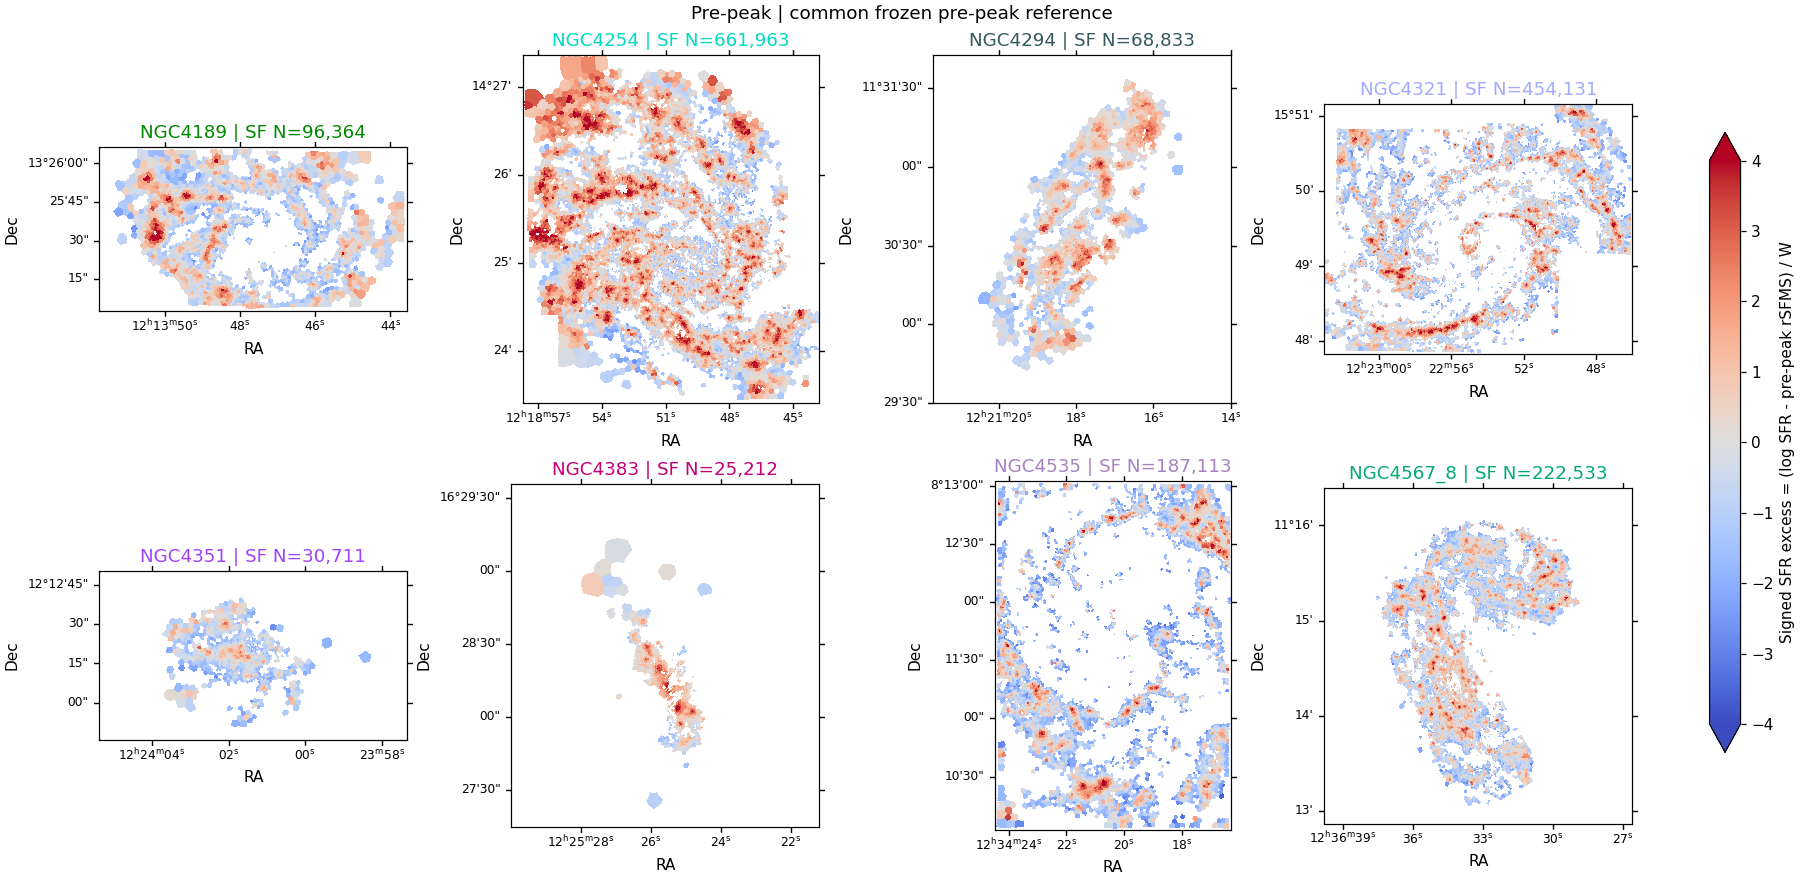

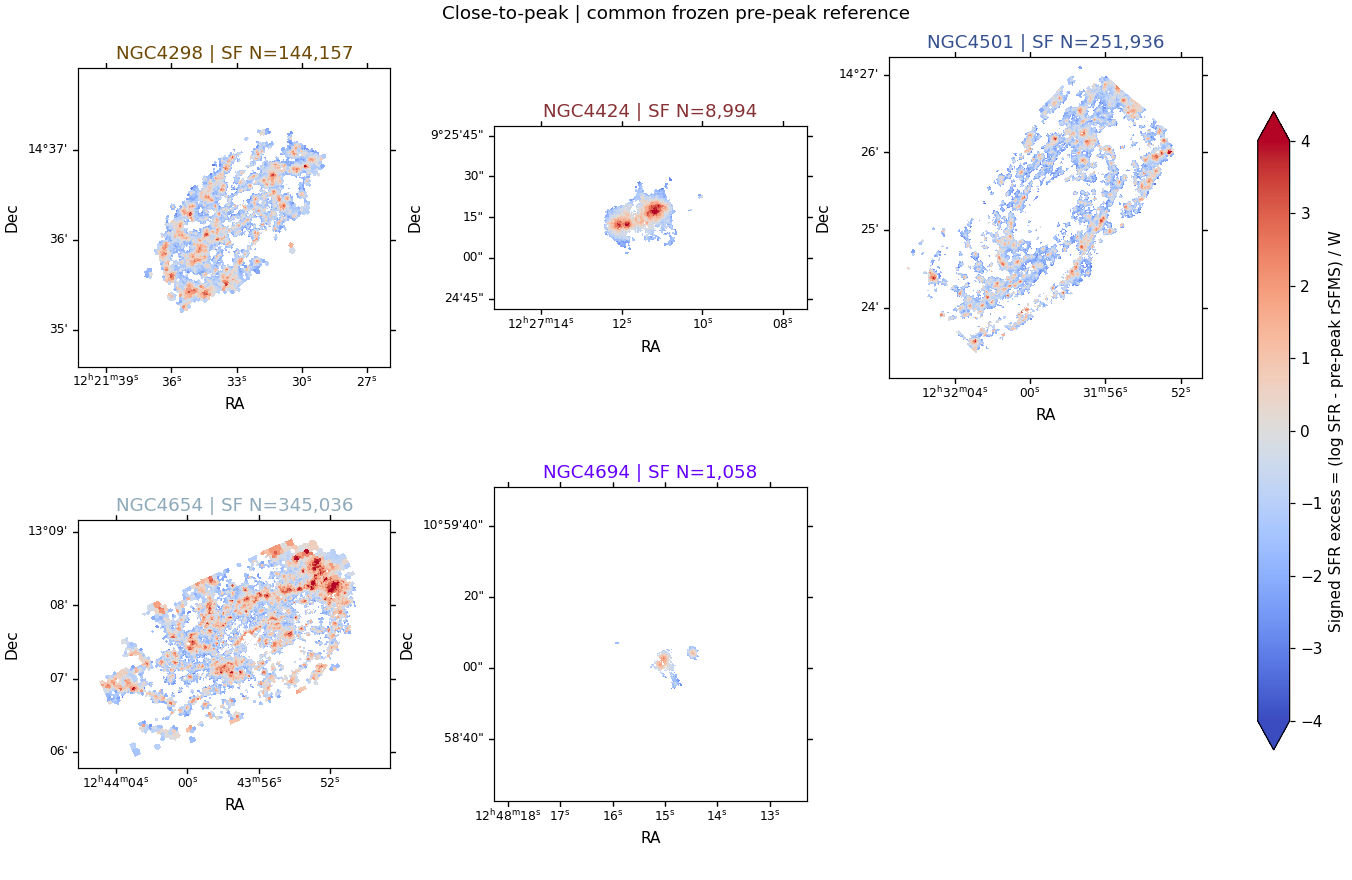

In [8]:
def plot_excess_maps(ids, stage_label):
    ncol = 3 if len(ids) <= 6 else 4
    nrow = int(np.ceil(len(ids)/ncol))
    fig = plt.figure(figsize=(4.1*ncol, 4.0*nrow), layout='constrained')
    axes = []
    for j, g in enumerate(ids):
        maps = galaxy_maps[g]
        ax = fig.add_subplot(nrow,ncol,j+1,projection=WCS(maps['header']).celestial)
        axes.append(ax)
        im = ax.imshow(maps['excess'],origin='lower',cmap='coolwarm',
            vmin=-MAP_LIMIT,vmax=MAP_LIMIT,interpolation='nearest')
        ax.set_title(f'{g} | SF N={len(samples[g]):,}', color=galaxy_colors[g])
        ax.coords[0].set_axislabel('RA')
        ax.coords[1].set_axislabel('Dec')
        ax.coords[0].set_ticklabel(size=8)
        ax.coords[1].set_ticklabel(size=8)
    fig.colorbar(im, ax=axes, shrink=.8, extend='both',
        label='Signed SFR excess = (log SFR - pre-peak rSFMS) / W')
    fig.suptitle(stage_label + ' | common frozen pre-peak reference')
    plt.show()
plot_excess_maps(pre_ids, 'Pre-peak')
plot_excess_maps(close_ids, 'Close-to-peak')

## 4. Five histogram panels: all pre-peak galaxies plus one close-to-peak

Each galaxy histogram integrates to one using identical bins covering the
entire selected excess range; no histogram tails are dropped. Every panel
shows all eight pre-peak products as thin solid curves and one close-to-peak
galaxy as a thick dashed curve. The black reference is the equal-galaxy mean
pre-peak histogram. Counts and >1/>2/>3 fractions remain in the preceding table.

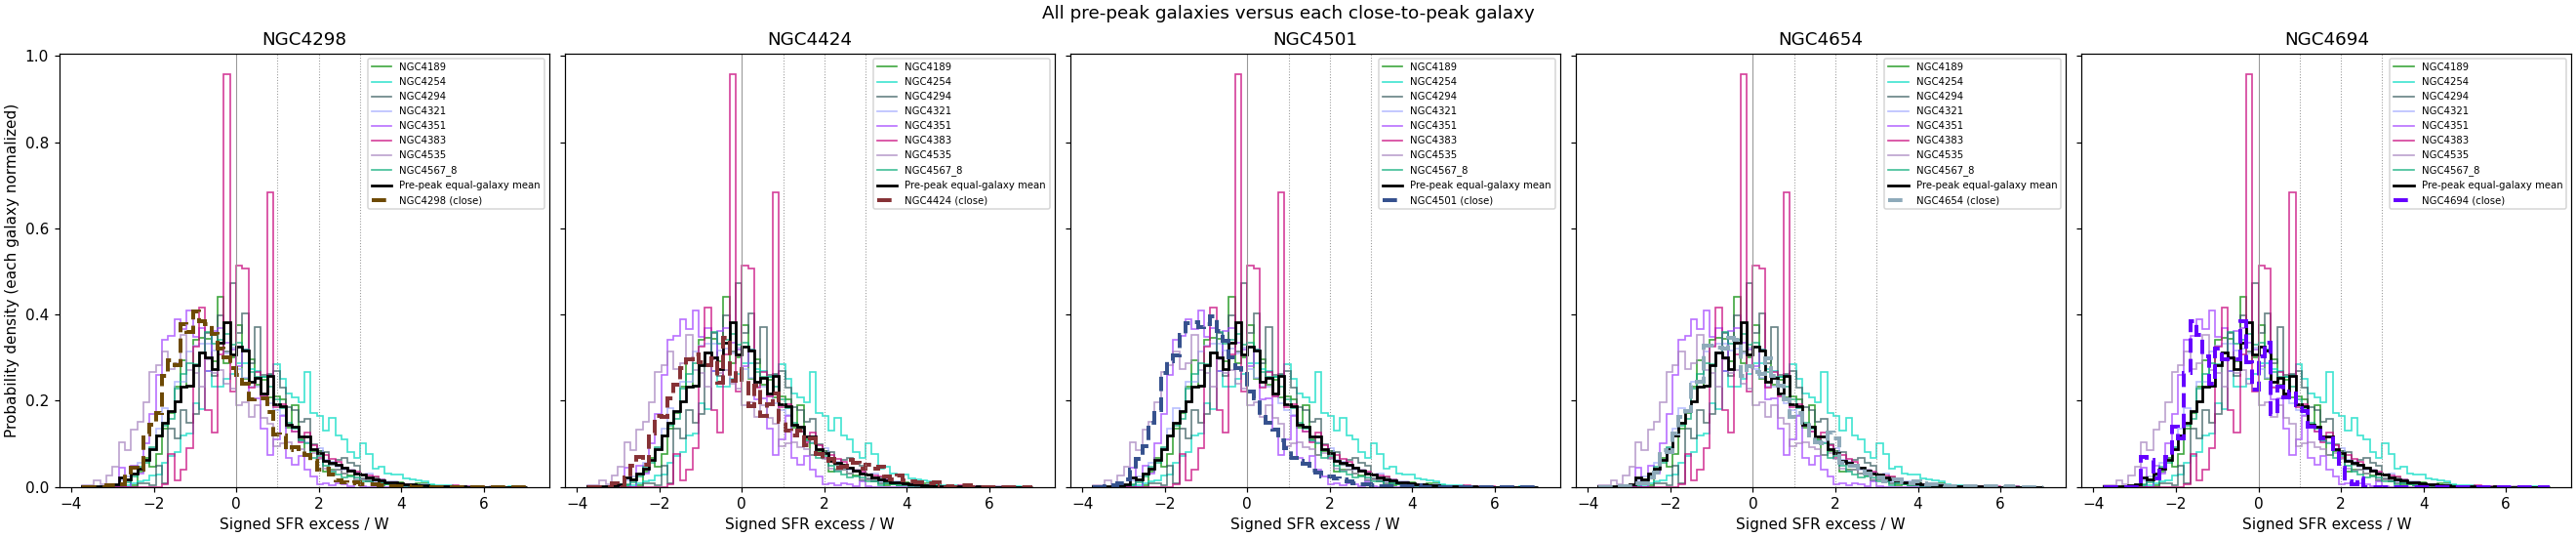

In [9]:
all_excess = np.concatenate([samples[g].excess.to_numpy() for g in pre_ids+close_ids])
bin_step = .15
hist_edges = np.arange(np.floor(all_excess.min()/bin_step)*bin_step,
    np.ceil(all_excess.max()/bin_step)*bin_step+2*bin_step, bin_step)
def histogram_density(g):
    counts, _ = np.histogram(samples[g].excess, bins=hist_edges)
    assert counts.sum() == len(samples[g])
    return counts / counts.sum() / np.diff(hist_edges)
pre_hist = {g: histogram_density(g) for g in pre_ids}
pooled_equal_hist = np.mean(list(pre_hist.values()), axis=0)
fig, axes = plt.subplots(1,len(close_ids),figsize=(24,5),sharex=True,sharey=True,
    layout='constrained')
for ax, close_g in zip(axes, close_ids):
    for g in pre_ids:
        ax.stairs(pre_hist[g],hist_edges,color=galaxy_colors[g],lw=1.1,alpha=.75,label=g)
    ax.stairs(pooled_equal_hist,hist_edges,color='black',lw=1.8,label='Pre-peak equal-galaxy mean')
    ax.stairs(histogram_density(close_g),hist_edges,color=galaxy_colors[close_g],
        lw=2.6,ls='--',label=close_g+' (close)')
    for threshold in (0,1,2,3):
        ax.axvline(threshold,color='0.6',ls=':' if threshold else '-',lw=.7)
    ax.set(title=close_g, xlabel='Signed SFR excess / W')
    ax.legend(fontsize=6.6,loc='upper right')
axes[0].set_ylabel('Probability density (each galaxy normalized)')
fig.suptitle('All pre-peak galaxies versus each close-to-peak galaxy')
plt.show()

## 5. Reproducibility checks and reading limits

The final checks verify equal fit weights, direct agreement with weighted
least squares, the exact mean-of-per-galaxy width calculation, and threshold
counts/map support. These checks validate the implementation, not a physical
enhancement claim. Shared gas bins and PSF correlations mean native spaxels
are not independent; the fractions describe the observed selected footprint
and have no binomial significance interpretation here. The in-sample pre-peak
width also omits uncertainty in the fitted reference.

In [10]:
design = np.column_stack([x, np.ones_like(x)])
independent_coef = np.linalg.lstsq(design*np.sqrt(weights)[:,None],
    y*np.sqrt(weights),rcond=None)[0]
np.testing.assert_allclose([slope,intercept],independent_coef,rtol=1e-9,atol=1e-9)
direct_width = np.mean([np.mean(np.sqrt(np.maximum(
    (f.y.to_numpy()-rsfms(f.x))**2 - f.sfr_err_dex.to_numpy()**2,0)))
    for g in pre_ids for f in [samples[g].loc[np.isfinite(samples[g].sfr_err_dex)]]])
np.testing.assert_allclose(width_dex,direct_width)
assert set(pre.GALID) == set(pre_ids)
assert not set(pre.GALID) & set(close_ids)
for row in fractions.itertuples(index=False):
    f = samples[row.GALID]
    emap = galaxy_maps[row.GALID]['excess']
    sf = galaxy_maps[row.GALID]['sf_mask']
    assert np.array_equal(np.isfinite(emap),sf)
    np.testing.assert_allclose(emap[sf],f.excess)
    assert row.N_excess_gt3 <= row.N_excess_gt2 <= row.N_excess_gt1 <= row.N_SF
    assert all(0 <= getattr(row,f'fraction_excess_gt{t}') <= 1 for t in (1,2,3))
    np.testing.assert_allclose(np.sum(histogram_density(row.GALID)*np.diff(hist_edges)),1)
print('CHECKS_OK:',len(pre_ids),'pre-peak products;',len(close_ids),'close-to-peak products')
print('Width:',width_dex,'dex; Python',platform.python_version())
print('No products or external figure/table files written; all figures use plt.show().')

CHECKS_OK: 8 pre-peak products; 5 close-to-peak products
Width: 0.3480022860096287 dex; Python 3.13.3
No products or external figure/table files written; all figures use plt.show().


## 6. Outer-disc repeat of cells 11 and 14: SF spaxels with R/Re > 1

Keep the **same all-footprint pre-peak rSFMS and W**. Repeat the threshold table
and three-panel histogram using only selected SF spaxels at strictly **R/Re > 1**.
R/Re is the existing deprojected elliptical radius using the adopted photometric
semimajor/semiminor effective radii. For NGC4567_8 the inherited radius is the
minimum of the two component radii: this cut is outside both component ellipses,
and the combined product still contributes one equal-weight reference histogram.
There is no outer radius limit, direction cut, or new reference fit.

Each threshold fraction uses the galaxy's **outer SF spaxels** as its denominator.
Zero outer-SF support is reported explicitly with undefined fractions/density,
not as a zero enhancement fraction. Histogram bins span all outer-SF excess
values and each nonempty galaxy is separately normalized; the black curve is
the equal-product mean of nonempty outer pre-peak histograms.

A double-horn shape could arise if near-reference and enhanced populations are
sufficiently separated and both contribute enough spaxels. Enhancement can also
appear as a single shifted peak, a shoulder, or a positive tail. Bimodality alone
does not identify its cause; these are residual-distribution histograms, not
velocity profiles. Inspect the spatial excess maps to locate any high-excess
population. Radial population differences and correlated/repeated gas-bin values
can also shape the histograms. This outer selection is a descriptive follow-up,
with no bimodality or RPS significance test.

The histogram panels share excess bins and x limits but use independent density
y scales, so a narrow low-count spike does not compress the other panels.

NGC4424 and NGC4694 are excluded from this outer-disc comparison at the user's
request; the original full-disc analysis retains them. The three close-to-peak
comparisons are NGC4298, NGC4501, and NGC4654.


In [16]:
# Outer-disc repeat of original cell 11; keep samples/fractions/maps unchanged.
outer_excluded_ids = {'NGC4424', 'NGC4694'}
outer_close_ids = [g for g in close_ids if g not in outer_excluded_ids]
outer_ids = pre_ids + outer_close_ids
outer_samples, outer_fraction_rows = {}, []
for g in outer_ids:
    f = samples[g].copy()
    radius = galaxy_maps[g]['radius_re'][
        f.pixel_y.to_numpy(dtype=int), f.pixel_x.to_numpy(dtype=int)]
    f['radius_re'] = radius
    outer_samples[g] = f.loc[np.isfinite(radius) & (radius > 1.0)].copy()
    outer = outer_samples[g]
    result = dict(GALID=g, stage=samples[g].stage.iloc[0], N_SF_all=len(f),
        N_SF_outer=len(outer), fraction_SF_outside_Re=len(outer)/len(f),
        mean_excess=outer.excess.mean(), median_excess=outer.excess.median(),
        fraction_outside_reference_x=outer.outside_reference_x.mean(),
        status='ok' if len(outer) else 'no SF spaxels at R/Re > 1')
    for threshold in (1,2,3):
        count = int(outer.excess.gt(threshold).sum())
        result[f'N_excess_gt{threshold}'] = count
        result[f'fraction_excess_gt{threshold}'] = count/len(outer) if len(outer) else np.nan
    outer_fraction_rows.append(result)
outer_fractions = pd.DataFrame(outer_fraction_rows)
outer_fraction_display = with_equal_prepeak_fraction_row(outer_fractions)
print('Pre-peak equal-galaxy row: mean of eight outer-SF per-product fractions; counts undefined.')
display(outer_fraction_display)
print('Outer SF only: R/Re > 1; frozen all-footprint reference; W =', width_dex, 'dex')
print(outer_fraction_display[['GALID','stage','N_SF_outer','fraction_excess_gt1',
    'fraction_excess_gt2','fraction_excess_gt3','status']].to_string(
        index=False, float_format=lambda v: f'{v:.4f}'))

Pre-peak equal-galaxy row: mean of eight outer-SF per-product fractions; counts undefined.
Outer SF only: R/Re > 1; frozen all-footprint reference; W = 0.3480022860096287 dex
                GALID         stage  N_SF_outer  fraction_excess_gt1  fraction_excess_gt2  fraction_excess_gt3 status
              NGC4189      pre-peak  54299.0000               0.2356               0.0704               0.0235     ok
              NGC4254      pre-peak 554478.0000               0.4158               0.1962               0.0732     ok
              NGC4294      pre-peak  47459.0000               0.2138               0.0607               0.0080     ok
              NGC4321      pre-peak 110913.0000               0.1858               0.0525               0.0163     ok
              NGC4351      pre-peak   5618.0000               0.0584               0.0000               0.0000     ok
              NGC4383      pre-peak  20253.0000               0.0994               0.0245               0.0055     ok

,GALID,stage,N_SF_all,N_SF_outer,fraction_SF_outside_Re,mean_excess,median_excess,fraction_outside_reference_x,status,N_excess_gt1,fraction_excess_gt1,N_excess_gt2,fraction_excess_gt2,N_excess_gt3,fraction_excess_gt3
0,NGC4189,pre-peak,96364.0,54299.0,0.563478,0.180748,0.067813,0.0,ok,12791.0,0.235566,3824.0,0.070425,1278.0,0.023536
1,NGC4254,pre-peak,661963.0,554478.0,0.837627,0.786536,0.685573,0.0,ok,230568.0,0.415829,108764.0,0.196156,40585.0,0.073195
2,NGC4294,pre-peak,68833.0,47459.0,0.689480,0.174142,0.077715,0.0,ok,10147.0,0.213806,2881.0,0.060705,381.0,0.008028
3,NGC4321,pre-peak,454131.0,110913.0,0.244231,-0.191756,-0.360578,0.0,ok,20610.0,0.185821,5822.0,0.052492,1804.0,0.016265
4,NGC4351,pre-peak,30711.0,5618.0,0.182931,-0.835318,-0.960518,0.0,ok,328.0,0.058384,0.0,0.000000,0.0,0.000000
5,NGC4383,pre-peak,25212.0,20253.0,0.803308,0.071348,-0.026506,0.0,ok,2013.0,0.099393,497.0,0.024540,111.0,0.005481
6,NGC4535,pre-peak,187113.0,122031.0,0.652178,-0.393814,-0.561324,0.0,ok,20216.0,0.165663,7512.0,0.061558,2232.0,0.018290
7,NGC4567_8,pre-peak,222533.0,65601.0,0.294792,-0.364643,-0.463929,0.0,ok,7537.0,0.114892,1766.0,0.026920,367.0,0.005594
8,Pre-peak equal-galaxy,pre-peak,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.186169,NaN,0.061599,NaN,0.018799
9,NGC4298,close-to-peak,144157.0,70531.0,0.489265,-0.427821,-0.619733,0.0,ok,8673.0,0.122967,2139.0,0.030327,316.0,0.004480


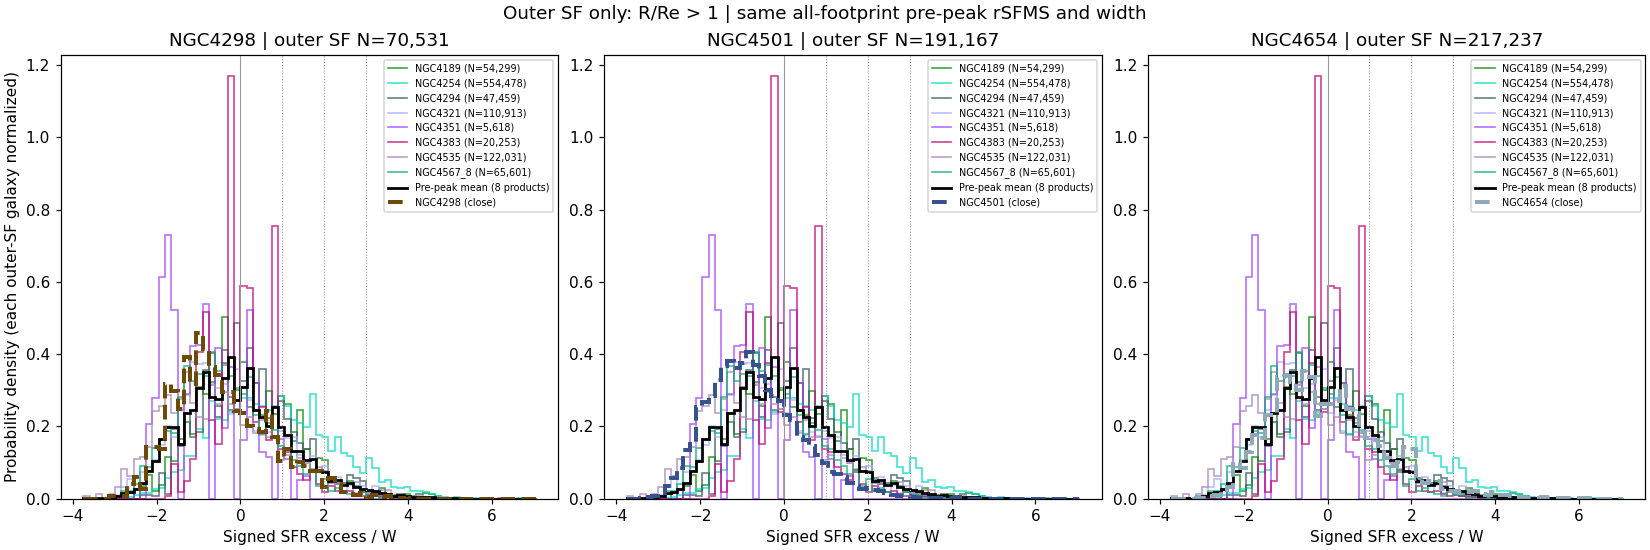

In [12]:
# Outer-disc repeat of original cell 14; retain the original histogram variables.
outer_pre_ids = [g for g in pre_ids if len(outer_samples[g])]
outer_supported_ids = [g for g in outer_ids if len(outer_samples[g])]
if not outer_pre_ids:
    raise ValueError('No outer pre-peak SF support for the reference histogram')
outer_all_excess = np.concatenate([outer_samples[g].excess.to_numpy() for g in outer_supported_ids])
outer_bin_step = .15
outer_hist_edges = np.arange(np.floor(outer_all_excess.min()/outer_bin_step)*outer_bin_step,
    np.ceil(outer_all_excess.max()/outer_bin_step)*outer_bin_step+2*outer_bin_step, outer_bin_step)
def outer_histogram_density(g):
    values = outer_samples[g].excess.to_numpy()
    if not len(values):
        return np.full(len(outer_hist_edges)-1,np.nan)
    counts, _ = np.histogram(values,bins=outer_hist_edges)
    assert counts.sum() == len(values)
    return counts/counts.sum()/np.diff(outer_hist_edges)
outer_pre_hist = {g: outer_histogram_density(g) for g in outer_pre_ids}
outer_equal_hist = np.mean(list(outer_pre_hist.values()),axis=0)
fig, axes = plt.subplots(1,len(outer_close_ids),figsize=(15,5),sharex=True,sharey=False,
    layout='constrained')
for ax, close_g in zip(axes,outer_close_ids):
    for g in pre_ids:
        if g in outer_pre_hist:
            ax.stairs(outer_pre_hist[g],outer_hist_edges,color=galaxy_colors[g],
                lw=1.1,alpha=.75,label=f'{g} (N={len(outer_samples[g]):,})')
        else:
            ax.plot([],[],color=galaxy_colors[g],label=g+' (no outer SF)')
    ax.stairs(outer_equal_hist,outer_hist_edges,color='black',lw=1.8,
        label=f'Pre-peak mean ({len(outer_pre_ids)} products)')
    if len(outer_samples[close_g]):
        ax.stairs(outer_histogram_density(close_g),outer_hist_edges,
            color=galaxy_colors[close_g],lw=2.6,ls='--',label=close_g+' (close)')
    else:
        ax.text(.05,.55,'No outer SF spaxels',transform=ax.transAxes)
    for threshold in (0,1,2,3):
        ax.axvline(threshold,color='0.6',ls=':' if threshold else '-',lw=.7)
    ax.set(title=f'{close_g} | outer SF N={len(outer_samples[close_g]):,}',
        xlabel='Signed SFR excess / W')
    ax.legend(fontsize=6.3,loc='upper right')
axes[0].set_ylabel('Probability density (each outer-SF galaxy normalized)')
fig.suptitle('Outer SF only: R/Re > 1 | same all-footprint pre-peak rSFMS and width')
plt.show()

In [13]:
assert not set(outer_fractions.GALID) & outer_excluded_ids
assert outer_close_ids == ['NGC4298', 'NGC4501', 'NGC4654']
# Check strict radius selection, fixed excess, outer denominators, and full histograms.
for row in outer_fractions.itertuples(index=False):
    g = row.GALID
    f, outer = samples[g], outer_samples[g]
    radius = galaxy_maps[g]['radius_re'][f.pixel_y.to_numpy(dtype=int), f.pixel_x.to_numpy(dtype=int)]
    expected = np.isfinite(radius) & (radius > 1)
    assert len(outer) == int(expected.sum()) == row.N_SF_outer
    assert (outer.radius_re > 1).all()
    np.testing.assert_allclose(outer.excess,(outer.y-rsfms(outer.x))/width_dex)
    assert row.N_excess_gt3 <= row.N_excess_gt2 <= row.N_excess_gt1 <= row.N_SF_outer
    for threshold in (1,2,3):
        reported = getattr(row,f'fraction_excess_gt{threshold}')
        if len(outer):
            np.testing.assert_allclose(reported,np.mean(outer.excess.to_numpy() > threshold))
        else:
            assert np.isnan(reported)
    if len(outer):
        np.testing.assert_allclose(np.sum(outer_histogram_density(g)*np.diff(outer_hist_edges)),1)
np.testing.assert_allclose(np.sum(outer_equal_hist*np.diff(outer_hist_edges)),1)
print('OUTER_CHECKS_OK: strict R/Re > 1; original reference and full-disc cells preserved')

OUTER_CHECKS_OK: strict R/Re > 1; original reference and full-disc cells preserved


NW_SECTOR_CHECKS_OK: 126,662 / 345,036 NGC4654 SF spaxels (36.71%); east < 0 and north > 0; all radii retained.


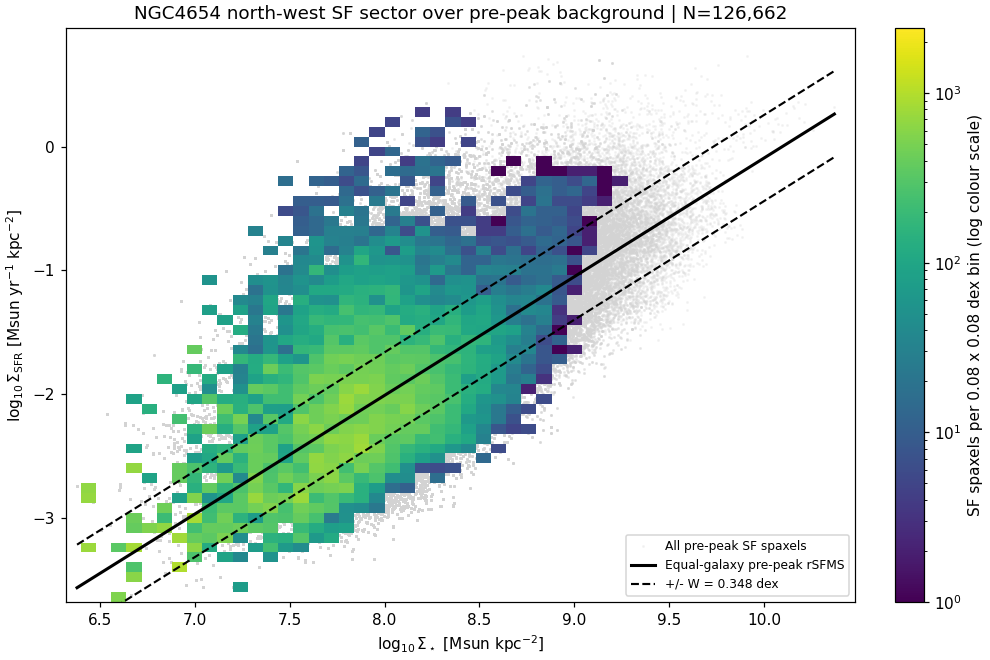

In [18]:
# Additional exploratory cell-10 comparison: NGC4654 north-west SF sector only.
# NW means east < 0 AND north > 0 relative to the adopted galaxy centre,
# determined from celestial WCS, not array orientation or deprojected disc PA.
# Retain all radii in this quadrant; the only new selection is sky sector.
# The pre-peak background, line, width, bins and colour scale are frozen to cell 10.
# This selected-region plot is descriptive, not a significance test.
nw_galid = 'NGC4654'
nw_full = samples[nw_galid]
nw_geometry = geometry.loc[geometry.notebook_product_id.eq(nw_galid)]
assert len(nw_geometry) == 1, 'NW sector requires one adopted centre'
nw_centre = nw_geometry.iloc[0]
nw_wcs = WCS(galaxy_maps[nw_galid]['header']).celestial
nw_ra, nw_dec = nw_wcs.pixel_to_world_values(
    nw_full.pixel_x.to_numpy(dtype=int), nw_full.pixel_y.to_numpy(dtype=int))
nw_east, nw_north = tangent_offsets_arcsec(nw_ra,nw_dec,
    nw_centre.center_ra_deg,nw_centre.center_dec_deg)
nw_take = np.isfinite(nw_east) & np.isfinite(nw_north) & (nw_east < 0) & (nw_north > 0)
nw_sf = nw_full.loc[nw_take].copy()
if nw_sf.empty: raise ValueError('NGC4654 has no selected SF spaxels in the NW sky quadrant')
nw_counts, _, _ = np.histogram2d(nw_sf.x,nw_sf.y,bins=(overlay_x_edges,overlay_y_edges))
assert int(nw_counts.sum()) == len(nw_sf), 'NW histogram lost spaxels'
assert (nw_east[nw_take] < 0).all() and (nw_north[nw_take] > 0).all()
assert len(nw_sf) == int(nw_take.sum())
fig, ax = plt.subplots(figsize=(9,6),layout='constrained')
ax.scatter(pre.x,pre.y,s=1,color='lightgray',alpha=.20,rasterized=True,
    label='All pre-peak SF spaxels',zorder=1)
nw_mesh = ax.pcolormesh(overlay_x_edges,overlay_y_edges,np.ma.masked_equal(nw_counts.T,0),
    cmap='viridis',norm=overlay_norm,shading='flat',rasterized=True,zorder=2)
ax.plot(overlay_line_x,rsfms(overlay_line_x),color='black',lw=2,
    label='Equal-galaxy pre-peak rSFMS',zorder=3)
ax.plot(overlay_line_x,rsfms(overlay_line_x)+width_dex,color='black',ls='--',lw=1.4,
    label=f'+/- W = {width_dex:.3f} dex',zorder=3)
ax.plot(overlay_line_x,rsfms(overlay_line_x)-width_dex,color='black',ls='--',lw=1.4,zorder=3)
ax.set(xlim=(overlay_x_edges[0],overlay_x_edges[-1]),
    ylim=(overlay_y_edges[0],overlay_y_edges[-1]),
    xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
    ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
    title=f'NGC4654 north-west SF sector over pre-peak background | N={len(nw_sf):,}')
fig.colorbar(nw_mesh,ax=ax,label='SF spaxels per 0.08 x 0.08 dex bin (log colour scale)')
ax.legend(fontsize=8,loc='lower right')
plt.show()
print(f'NW_SECTOR_CHECKS_OK: {len(nw_sf):,} / {len(nw_full):,} NGC4654 SF spaxels '
      f'({len(nw_sf)/len(nw_full):.2%}); east < 0 and north > 0; all radii retained.')

In [19]:
# Repeat the cell-19 threshold analysis for the NGC4654 NW sky quadrant,
# both without a radius cut and with strict R/Re > 1.
# Use the original all-footprint pre-peak rSFMS/width; no regional refit.
# Fractions describe selected SF spaxels, not independent significance tests.
nw_fraction_galid = 'NGC4654'
nw_fraction_full = samples[nw_fraction_galid]
nw_fraction_maps = galaxy_maps[nw_fraction_galid]
nw_fraction_geometry = geometry.loc[geometry.notebook_product_id.eq(nw_fraction_galid)]
assert len(nw_fraction_geometry) == 1
nw_fraction_centre = nw_fraction_geometry.iloc[0]
nw_fraction_px = nw_fraction_full.pixel_x.to_numpy(dtype=int)
nw_fraction_py = nw_fraction_full.pixel_y.to_numpy(dtype=int)
nw_fraction_ra, nw_fraction_dec = WCS(nw_fraction_maps['header']).celestial.pixel_to_world_values(
    nw_fraction_px,nw_fraction_py)
nw_fraction_east, nw_fraction_north = tangent_offsets_arcsec(
    nw_fraction_ra,nw_fraction_dec,nw_fraction_centre.center_ra_deg,nw_fraction_centre.center_dec_deg)
nw_fraction_radius = nw_fraction_maps['radius_re'][nw_fraction_py,nw_fraction_px]
nw_fraction_mask = (np.isfinite(nw_fraction_east) & np.isfinite(nw_fraction_north)
    & (nw_fraction_east < 0) & (nw_fraction_north > 0))
nw_fraction_outer_mask = nw_fraction_mask & np.isfinite(nw_fraction_radius) & (nw_fraction_radius > 1.0)
nw_fraction_rows = []
for label, take in [('NW: all radii',nw_fraction_mask), ('NW: R/Re > 1',nw_fraction_outer_mask)]:
    selected_nw = nw_fraction_full.loc[take].copy()
    # Derive from the frozen line again to verify the stored excess values.
    selected_excess = (selected_nw.y.to_numpy()-rsfms(selected_nw.x.to_numpy()))/width_dex
    np.testing.assert_allclose(selected_excess,selected_nw.excess.to_numpy())
    result = dict(GALID=nw_fraction_galid, stage=nw_fraction_full.stage.iloc[0],
        selection=label, N_SF=len(selected_nw), N_SF_NW_all=int(nw_fraction_mask.sum()),
        fraction_of_NW_SF=len(selected_nw)/nw_fraction_mask.sum() if nw_fraction_mask.any() else np.nan,
        mean_excess=selected_nw.excess.mean(), median_excess=selected_nw.excess.median(),
        fraction_outside_reference_x=selected_nw.outside_reference_x.mean(),
        status='ok' if len(selected_nw) else 'no selected SF spaxels')
    for threshold in (1,2,3):
        n_excess = int(np.sum(selected_excess > threshold))
        result[f'N_excess_gt{threshold}'] = n_excess
        result[f'fraction_excess_gt{threshold}'] = n_excess/len(selected_nw) if len(selected_nw) else np.nan
    nw_fraction_rows.append(result)
nw_sector_fractions = pd.DataFrame(nw_fraction_rows)
display(nw_sector_fractions)
print('NGC4654 NW = east < 0 and north > 0; unchanged pre-peak W =',width_dex,'dex')
print('Each fraction denominator is N_SF in that row, not the whole galaxy.')
print(nw_sector_fractions[['GALID','selection','N_SF','fraction_excess_gt1',
    'fraction_excess_gt2','fraction_excess_gt3','status']].to_string(
        index=False,float_format=lambda v:f'{v:.4f}'))
assert np.all(~nw_fraction_outer_mask | nw_fraction_mask)
assert (nw_fraction_east[nw_fraction_mask] < 0).all() and (nw_fraction_north[nw_fraction_mask] > 0).all()
assert (nw_fraction_radius[nw_fraction_outer_mask] > 1).all()
for row in nw_sector_fractions.itertuples(index=False):
    assert row.N_excess_gt3 <= row.N_excess_gt2 <= row.N_excess_gt1 <= row.N_SF
    for t in (1,2,3):
        f = getattr(row,f'fraction_excess_gt{t}')
        if row.N_SF:
            np.testing.assert_allclose(f,getattr(row,f'N_excess_gt{t}')/row.N_SF)
        else:
            assert np.isnan(f)
print('NW_FRACTION_CHECKS_OK: both NW selections; strict cuts; row-specific denominators')

NGC4654 NW = east < 0 and north > 0; unchanged pre-peak W = 0.3480022860096287 dex
Each fraction denominator is N_SF in that row, not the whole galaxy.
  GALID     selection   N_SF  fraction_excess_gt1  fraction_excess_gt2  fraction_excess_gt3 status
NGC4654 NW: all radii 126662               0.2769               0.1199               0.0441     ok
NGC4654  NW: R/Re > 1  81294               0.3141               0.1419               0.0584     ok
NW_FRACTION_CHECKS_OK: both NW selections; strict cuts; row-specific denominators


,GALID,stage,selection,N_SF,N_SF_NW_all,fraction_of_NW_SF,mean_excess,median_excess,fraction_outside_reference_x,status,N_excess_gt1,fraction_excess_gt1,N_excess_gt2,fraction_excess_gt2,N_excess_gt3,fraction_excess_gt3
0,NGC4654,close-to-peak,NW: all radii,126662,126662,1.000000,0.303264,0.121725,0.0,ok,35071,0.276887,15191,0.119933,5588,0.044117
1,NGC4654,close-to-peak,NW: R/Re > 1,81294,126662,0.641818,0.454911,0.306516,0.0,ok,25534,0.314095,11537,0.141917,4750,0.058430
